# Exercise 1 · Sentiment analysis

**Mục tiêu.** Minh họa cách DistilBERT đã fine-tune trên SST-2 xử lý một câu tiếng Anh.

Chạy `python src/1_sentiment.py` và `python visualization/plot_sentiment.py` trong thư mục workflow. Notebook đọc kết quả đã tạo.

In [1]:
import json
from pathlib import Path
from IPython.display import Image, display

root = Path.cwd()
result_path = root / "outputs" / "sentiment_result.json"
if not result_path.is_file():
    raise FileNotFoundError("Open this notebook in its workflow and run src/1_sentiment.py first.")
result = json.loads(result_path.read_text(encoding="utf-8"))
print("Model:", result["model_id"])
print("Sentence:", result["sentence"])
for token, token_id, mask in zip(result["tokens"], result["token_ids"], result["attention_mask"]):
    print(f"{token:>16}  {token_id:>6}  mask={mask}")

Model: distilbert/distilbert-base-uncased-finetuned-sst-2-english
Sentence: The film started slowly, but I absolutely loved its ending.
           [CLS]     101  mask=1
             the    1996  mask=1
            film    2143  mask=1
         started    2318  mask=1
          slowly    3254  mask=1
               ,    1010  mask=1
             but    2021  mask=1
               i    1045  mask=1
      absolutely    7078  mask=1
           loved    3866  mask=1
             its    2049  mask=1
          ending    4566  mask=1
               .    1012  mask=1
           [SEP]     102  mask=1


POSITIVE · 99.98%
Logits: {'NEGATIVE': -4.18034553527832, 'POSITIVE': 4.421328544616699}
Softmax: {'NEGATIVE': 0.00018376407388132066, 'POSITIVE': 0.9998162388801575}


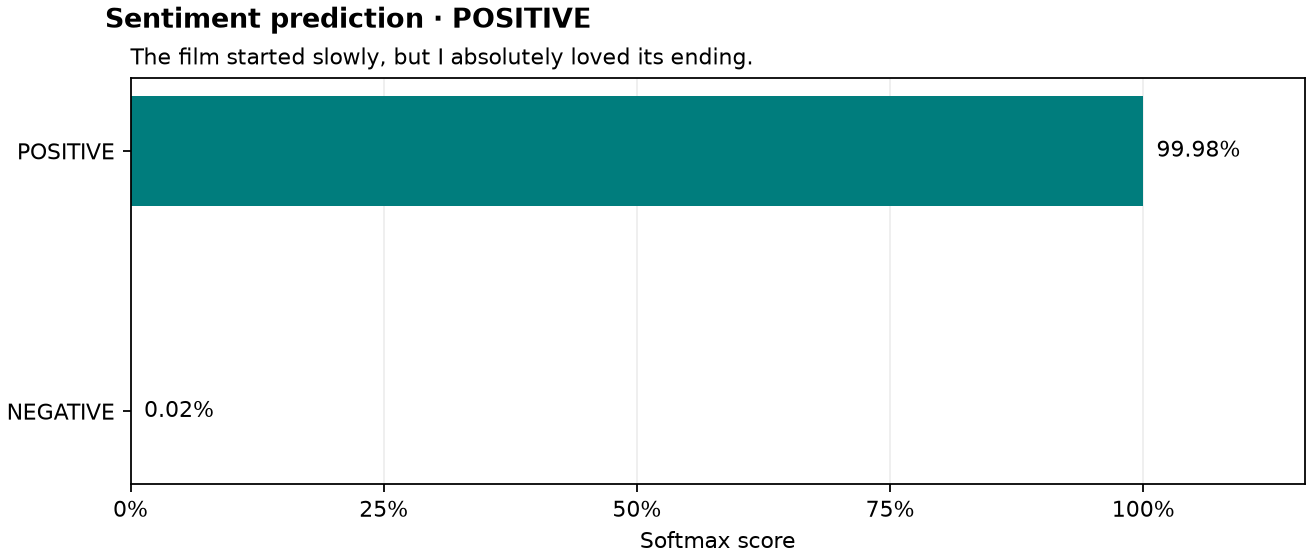

In [2]:
print(f'{result["predicted_label"]} · {result["confidence"]:.2%}')
print("Logits:", result["logits"])
print("Softmax:", result["scores"])
plot = root / "visualization" / "sentiment_scores.png"
if plot.exists():
    display(Image(filename=str(plot)))

## Câu hỏi khi trình bày

Token IDs được dùng ở lớp nào? Attention mask có giá trị gì trong câu này? Điểm softmax mô tả điều gì trên câu vừa chạy?

[Giải thích chi tiết](docs/Tokenization_and_Inference.md) · [Hỏi đáp](docs/Model_QA.md)